# 1. ViT 실습

In [ ]:
from itertools import chain
from collections import defaultdict
from torch.utils.data import Subset
from torchvision import datasets

def subset_sampler(dataset, classes, max_len):
  target_idx = defaultdict(list)
  for idx, label in enumerate (dataset.train_labels):
    target_idx[int(label)].append(idx)

  indices = list(
      chain.from_iterable(
          [target_idx[idx][:max_len] for idx in range(len(classes))]
      )
  )

  return Subset(dataset, indices)

train_dataset = datasets.FashionMNIST(root="../datasets", download=True, train=True)
test_dataset = datasets.FashionMNIST(root="../datasets", download=True, train=False)

classes = train_dataset.classes
class_to_idx = train_dataset.class_to_idx

print(classes)
print(class_to_idx)

subset_train_dataset = subset_sampler(
      dataset = train_dataset, classes=train_dataset.classes, max_len=1000
)
subset_test_dataset = subset_sampler(
      dataset = test_dataset, classes=test_dataset.classes, max_len=100
)

print(f"Training Data SIze : {len(subset_train_dataset)}")
print(f"Testing Data Size : {len(subset_test_dataset)}")
print(train_dataset[0])

100%|██████████| 26.4M/26.4M [00:00<00:00, 121MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 7.88MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 62.8MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 21.9MB/s]
/usr/local/lib/python3.13/dist-packages/torchvision/datasets/mnist.py:66: UserWarning: train_labels has been renamed targets
  warnings.warn("train_labels has been renamed targets")


['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
{'T-shirt/top': 0, 'Trouser': 1, 'Pullover': 2, 'Dress': 3, 'Coat': 4, 'Sandal': 5, 'Shirt': 6, 'Sneaker': 7, 'Bag': 8, 'Ankle boot': 9}
Training Data SIze : 10000
Testing Data Size : 1000
(<PIL.Image.Image image mode=L size=28x28 at 0x7BE3D603C050>, 9)


In [ ]:
#10.2 이미지 전처리
import torch
from torchvision import transforms
from transformers import AutoImageProcessor

image_processor = AutoImageProcessor.from_pretrained(
    pretrained_model_name_or_path = "google/vit-base-patch16-224-in21k"
)

transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Resize(
            size = (
                image_processor.size["height"],
                image_processor.size["width"]
            )
        ),
        transforms.Lambda(
            lambda x: torch.cat([x, x, x], 0)
        ),
        transforms.Normalize(
            mean = image_processor.image_mean,
            std = image_processor.image_std
        )
    ]
)

print(f"size : {image_processor.size}")
print(f"mean : {image_processor.image_mean}")
print(f"std : {image_processor.image_std}")

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

size : SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
mean : (0.5, 0.5, 0.5)
std : (0.5, 0.5, 0.5)


In [ ]:
#10.3 ViT 데이터로더 적용
from torch.utils.data import DataLoader

def collator(data, transform):
  images, labels = zip(*data)
  pixel_values = torch.stack([transform(image) for image in images])
  labels = torch.tensor([label for label in labels])
  return {"pixel_values": pixel_values, "labels": labels}

train_dataloader = DataLoader(
    subset_train_dataset,
    batch_size = 32,
    shuffle=True,
    collate_fn = lambda x: collator(x, transform),
    drop_last = True
)

valid_dataloader = DataLoader(
    subset_test_dataset,
    batch_size=4,
    shuffle=True,
    collate_fn = lambda x: collator(x, transform),
    drop_last = True
)

batch = next(iter(train_dataloader))
for key, value in batch.items():
  print(f"{key} : {value.shape}")

pixel_values : torch.Size([32, 3, 224, 224])
labels : torch.Size([32])


In [ ]:
#10.4 사전 학습된 ViT 모델
from transformers import ViTForImageClassification

model = ViTForImageClassification.from_pretrained(
    pretrained_model_name_or_path="google/vit-base-patch16-224-in21k",
    num_labels=len(classes),
    id2label={idx: label for label, idx in class_to_idx.items()},
    label2id=class_to_idx,
    ignore_mismatched_sizes=True
)

print(model.classifier)

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Linear(in_features=768, out_features=10, bias=True)


In [ ]:
#10.5 패치 임베딩 확인
print(model.vit.embeddings)

btach = next(iter(train_dataloader))
print("image shape :", btach["pixel_values"].shape)
print("patch embeddings shape :",
      model.vit.embeddings.patch_embeddings(batch["pixel_values"]).shape)
print("[CLS] + patch embeddings shape : ",
      model.vit.embeddings(batch["pixel_values"]).shape)

ViTEmbeddings(
  (patch_embeddings): ViTPatchEmbeddings(
    (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  )
  (dropout): Dropout(p=0.0, inplace=False)
)
image shape : torch.Size([32, 3, 224, 224])
patch embeddings shape : torch.Size([32, 196, 768])
[CLS] + patch embeddings shape :  torch.Size([32, 197, 768])


In [ ]:
#10.6 하이퍼파라미터 설정
from transformers import TrainingArguments

args = TrainingArguments(
    output_dir="../models/ViT-FashionMNIST",
    save_strategy = "epoch",
    eval_strategy = "epoch",
    learning_rate = 1e-5,
    per_device_train_batch_size = 16,
    per_device_eval_batch_size = 16,
    num_train_epochs = 3,
    weight_decay = 0.001,
    load_best_model_at_end = True,
    metric_for_best_model = "f1",
    #logging_dir = "logs",
    logging_steps = 125,
    remove_unused_columns = False,
    seed = 7
)

In [ ]:
!pip install evaluate

In [ ]:
#10.7 매크로 평균 F! 점수
import evaluate
import numpy as np

def compute_metrics(eval_pred):
  metric = evaluate.load("f1")
  predictions, labels = eval_pred
  predictions = np.argmax(predictions, axis=1)
  macro_f1 = metric.compute(
      predictions=predictions, references=labels, average="macro"
  )
  return macro_f1

In [ ]:
#10.8 ViT 모델 학습
import torch
import evaluate
import numpy as np
from itertools import chain
from collections import defaultdict
from torch.utils.data import Subset
from torchvision import datasets
from torchvision import transforms
from transformers import AutoImageProcessor
from transformers import ViTForImageClassification
from transformers import TrainingArguments, Trainer

def subset_sampler(dataset, classes, max_len):
  target_idx = defaultdict(list)
  for idx, label in enumerate (dataset.train_labels):
    target_idx[int(label)].append(idx)

  indices = list(
      chain.from_iterable(
          [target_idx[idx][:max_len] for idx in range(len(classes))]
      )
  )

  return Subset(dataset, indices)

def model_init(classes, class_to_idx):
  model = ViTForImageClassification.from_pretrained(
      pretrained_model_name_or_path="google/vit-base-patch16-224-in21k",
      num_labels=len(classes),
      id2label={idx: label for label, idx in class_to_idx.items()},
      label2id=class_to_idx,
  )
  return model

def collator(data, transform):
  images, labels = zip(*data)
  pixel_values = torch.stack([transform(image) for image in images])
  labels = torch.tensor([label for label in labels])
  return {"pixel_values": pixel_values, "labels": labels}

def compute_metrics(eval_pred):
  metric = evaluate.load('f1')
  predictions, labels = eval_pred
  predictions = np.argmax(predictions, axis=1)
  macro_f1 = metric.compute(
      predictions=predictions, references=labels, average='macro'
  )
  return macro_f1

train_dataset = datasets.FashionMNIST(root="../datasets", download=True, train=True)
test_dataset = datasets.FashionMNIST(root="../datasets", download=True, train=False)

classes = train_dataset.classes
class_to_idx = train_dataset.class_to_idx

subset_train_dataset = subset_sampler(
      dataset = train_dataset, classes=train_dataset.classes, max_len=200
)
subset_test_dataset = subset_sampler(
      dataset = test_dataset, classes=test_dataset.classes, max_len=100
)

image_processor = AutoImageProcessor.from_pretrained(
    pretrained_model_name_or_path = "google/vit-base-patch16-224-in21k"
)

transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Resize(
            size = (
                image_processor.size["height"],
                image_processor.size["width"]
            )
        ),
        transforms.Lambda(
            lambda x: torch.cat([x, x, x], 0)
        ),
        transforms.Normalize(
            mean = image_processor.image_mean,
            std = image_processor.image_std
        )
    ]
)

args = TrainingArguments(
    output_dir="../models/ViT-FashionMNIST",
    save_strategy = "epoch",
    eval_strategy = "epoch",
    learning_rate = 1e-5,
    per_device_train_batch_size = 16,
    per_device_eval_batch_size = 16,
    num_train_epochs = 2,
    weight_decay = 0.001,
    load_best_model_at_end = True,
    metric_for_best_model = "f1",
    #logging_dir = "logs",
    logging_steps = 125,
    remove_unused_columns = False,
    seed = 7
)

trainer = Trainer(
    model_init=lambda x: model_init(classes, class_to_idx),
    args = args,
    train_dataset = subset_train_dataset,
    eval_dataset = subset_test_dataset,
    data_collator = lambda x: collator(x, transform),
    compute_metrics = compute_metrics,
    processing_class = image_processor,
)
trainer.train()

/usr/local/lib/python3.13/dist-packages/torchvision/datasets/mnist.py:66: UserWarning: train_labels has been renamed targets
  warnings.warn("train_labels has been renamed targets")


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,F1
1,1.968752,1.673084,0.803793
2,1.532633,1.473471,0.800207


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['vit.layers.0.attention.q_proj.weight', 'vit.layers.0.attention.q_proj.bias', 'vit.layers.0.attention.k_proj.weight', 'vit.layers.0.attention.k_proj.bias', 'vit.layers.0.attention.v_proj.weight', 'vit.layers.0.attention.v_proj.bias', 'vit.layers.0.attention.o_proj.weight', 'vit.layers.0.attention.o_proj.bias', 'vit.layers.0.layernorm_before.weight', 'vit.layers.0.layernorm_before.bias', 'vit.layers.0.layernorm_after.weight', 'vit.layers.0.layernorm_after.bias', 'vit.layers.0.mlp.fc1.weight', 'vit.layers.0.mlp.fc1.bias', 'vit.layers.0.mlp.fc2.weight', 'vit.layers.0.mlp.fc2.bias', 'vit.layers.1.attention.q_proj.weight', 'vit.layers.1.attention.q_proj.bias', 'vit.layers.1.attention.k_proj.weight', 'vit.layers.1.attention.k_proj.bias', 'vit.layers.1.attention.v_proj.weight', 'vit.layers.1.attention.v_proj.bias', 'vit.layers.1.attention.o_proj.weight', 'vit.layers.1.attention.o_proj.bias', 'vit.layers.1.layernorm_before

TrainOutput(global_step=250, training_loss=1.7506922607421875, metrics={'train_runtime': 223.9102, 'train_samples_per_second': 17.864, 'train_steps_per_second': 1.117, 'total_flos': 3.09990183616512e+17, 'train_loss': 1.7506922607421875, 'epoch': 2.0})

PredictionOutput(predictions=array([[ 0.7886248 , -0.30205965,  0.34845567, ..., -0.38853395,
        -0.16488545, -0.38623282],
       [ 0.20586807,  0.12018119, -0.04298014, ..., -0.38237235,
        -0.1737589 , -0.37074772],
       [ 0.5230957 , -0.39205506,  0.19460402, ...,  0.00406052,
         0.13128488, -0.22401121],
       ...,
       [-0.26336548, -0.37540558, -0.22992782, ...,  0.4346251 ,
         0.13746192,  1.0322297 ],
       [-0.15822038, -0.3998645 , -0.5420252 , ...,  0.80332214,
        -0.04975822,  1.2738004 ],
       [-0.22594464, -0.2965516 , -0.25717756, ...,  0.24517204,
         0.06284323,  1.1824218 ]], dtype=float32), label_ids=array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 

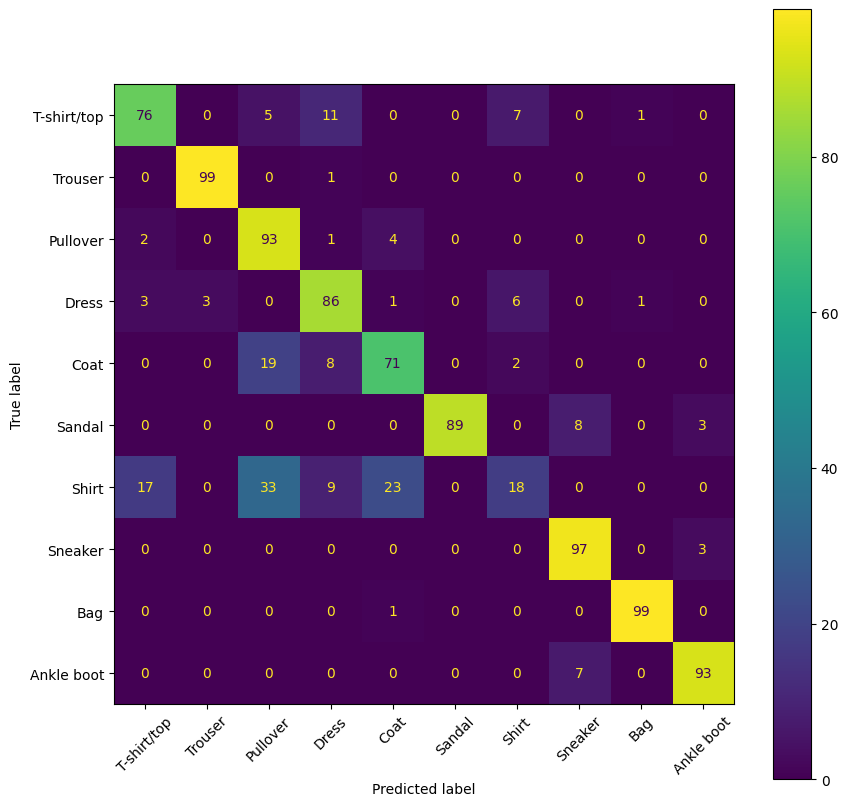

In [ ]:
#10.9 ViT 모델 성능 평가
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

outputs = trainer.predict(subset_test_dataset)
print(outputs)

y_true = outputs.label_ids
y_pred = outputs.predictions.argmax(1)

labels = list(classes)
matrix = confusion_matrix(y_true, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=labels)
_, ax = plt.subplots(figsize=(10, 10))
display.plot(xticks_rotation=45, ax=ax)
plt.show()

# 2. Swin Transformer

In [ ]:
#10.10 상대적 위치 편향 계산
import torch

window_size = 2
coords_h = torch.arange(window_size)
coords_w = torch.arange(window_size)
coords = torch.stack(torch.meshgrid([coords_h, coords_w], indexing='ij'))
coords_flatten = torch.flatten(coords, 1)
relative_coords = coords_flatten[:, :, None] - coords_flatten[:, None, :]
print(relative_coords)
print(relative_coords.shape)

In [ ]:
#10.11 X, Y출에 대한 위치 행렬
x_coords = relative_coords[0, :, :]
y_coords = relative_coords[1, :, :]

x_coords += window_size - 1
y_coords += window_size - 1
x_coords *= 2 * window_size - 1
print(f"X축에 대한 행렬:\n{x_coords}\n")
print(f"Y축에 대한 행렬:\n{y_coords}\n")
relative_position_index = x_coords + y_coords
print(f"X, Y축에 대한 위치 행렬:\n{relative_position_index}")

In [ ]:
#10.12 X, Y축에 대한 상대적 위치 좌표 변환
num_heads = 1
relative_position_bias_table = torch.Tensor(
    torch.zeros((2*window_size - 1) * (2*window_size - 1), num_heads)
)

relative_position_bias = relative_position_bias_table[relative_position_index.view(-1)]
relative_position_bias = relative_position_bias.view(
    window_size * window_size, window_size * window_size, -1
)
print(relative_position_bias.shape)

# 2. Swin Transformer 실습

In [ ]:
from itertools import chain
from collections import defaultdict
from torch.utils.data import Subset
from torchvision import datasets

def subset_sampler(dataset, classes, max_len):
  target_idx = defaultdict(list)
  for idx, label in enumerate (dataset.train_labels):
    target_idx[int(label)].append(idx)

  indices = list(
      chain.from_iterable(
          [target_idx[idx][:max_len] for idx in range(len(classes))]
      )
  )

  return Subset(dataset, indices)

train_dataset = datasets.FashionMNIST(root="../datasets", download=True, train=True)
test_dataset = datasets.FashionMNIST(root="../datasets", download=True, train=False)

classes = train_dataset.classes
class_to_idx = train_dataset.class_to_idx

print(classes)
print(class_to_idx)

subset_train_dataset = subset_sampler(
      dataset = train_dataset, classes=train_dataset.classes, max_len=1000
)
subset_test_dataset = subset_sampler(
      dataset = test_dataset, classes=test_dataset.classes, max_len=100
)

print(f"Training Data SIze : {len(subset_train_dataset)}")
print(f"Testing Data Size : {len(subset_test_dataset)}")
print(train_dataset[0])

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 209kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.84MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 13.1MB/s]
/usr/local/lib/python3.13/dist-packages/torchvision/datasets/mnist.py:66: UserWarning: train_labels has been renamed targets
  warnings.warn("train_labels has been renamed targets")


['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
{'T-shirt/top': 0, 'Trouser': 1, 'Pullover': 2, 'Dress': 3, 'Coat': 4, 'Sandal': 5, 'Shirt': 6, 'Sneaker': 7, 'Bag': 8, 'Ankle boot': 9}
Training Data SIze : 10000
Testing Data Size : 1000
(<PIL.Image.Image image mode=L size=28x28 at 0x7FE1A8580050>, 9)


In [ ]:
#10.2 이미지 전처리
import torch
from torchvision import transforms
from transformers import AutoImageProcessor

image_processor = AutoImageProcessor.from_pretrained(
    pretrained_model_name_or_path = "google/vit-base-patch16-224-in21k"
)

transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Resize(
            size = (
                image_processor.size["height"],
                image_processor.size["width"]
            )
        ),
        transforms.Lambda(
            lambda x: torch.cat([x, x, x], 0)
        ),
        transforms.Normalize(
            mean = image_processor.image_mean,
            std = image_processor.image_std
        )
    ]
)

print(f"size : {image_processor.size}")
print(f"mean : {image_processor.image_mean}")
print(f"std : {image_processor.image_std}")

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

size : SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
mean : (0.5, 0.5, 0.5)
std : (0.5, 0.5, 0.5)


In [ ]:
#10.3 ViT 데이터로더 적용
from torch.utils.data import DataLoader

def collator(data, transform):
  images, labels = zip(*data)
  pixel_values = torch.stack([transform(image) for image in images])
  labels = torch.tensor([label for label in labels])
  return {"pixel_values": pixel_values, "labels": labels}

train_dataloader = DataLoader(
    subset_train_dataset,
    batch_size = 32,
    shuffle=True,
    collate_fn = lambda x: collator(x, transform),
    drop_last = True
)

valid_dataloader = DataLoader(
    subset_test_dataset,
    batch_size=4,
    shuffle=True,
    collate_fn = lambda x: collator(x, transform),
    drop_last = True
)

batch = next(iter(train_dataloader))
for key, value in batch.items():
  print(f"{key} : {value.shape}")

pixel_values : torch.Size([32, 3, 224, 224])
labels : torch.Size([32])


In [ ]:
#10.13 사전 학습된 스윈 트랜스포머 모델
from transformers import SwinForImageClassification

model = SwinForImageClassification.from_pretrained(
    pretrained_model_name_or_path='microsoft/swin-tiny-patch4-window7-224',
    num_labels=len(train_dataset.classes),
    id2label={idx: label for label, idx in train_dataset.class_to_idx.items()},
    label2id=train_dataset.class_to_idx,
    ignore_mismatched_sizes=True
)

for main_name, main_module in model.named_children():
  print(main_name)
  for sub_name, sub_module in main_module.named_children():
    print("L", sub_name)
    for ssub_name, ssub_module in sub_module.named_children():
      print("|  L", ssub_name)
      for sssub_name, sssub_module in ssub_module.named_children():
        if sssub_name == 'projection':
          print('|  | L', sssub_name, sssub_module)
        else:
          print('|  | L', sssub_name)

[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[transformers] SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([10, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


swin
L embeddings
|  L patch_embeddings
|  | L projection Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
|  L norm
|  L dropout
L encoder
|  L layers
|  | L 0
|  | L 1
|  | L 2
|  | L 3
L layernorm
L pooler
classifier


In [ ]:
#10.14 패치 임베딩 모듈
batch = next(iter(train_dataloader))
print('이미지 차원:', batch['pixel_values'].shape)

patch_emb_output, shape = model.swin.embeddings.patch_embeddings(batch['pixel_values'])
print('모듈:', model.swin.embeddings.patch_embeddings)
print('패치 임베딩 차원:', patch_emb_output.shape)

이미지 차원: torch.Size([32, 3, 224, 224])
모듈: SwinPatchEmbeddings(
  (projection): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
)
패치 임베딩 차원: torch.Size([32, 3136, 96])


In [ ]:
#10.15 스윈 트랜스포머 블록
for main_name, main_module in model.swin.encoder.layers[0].named_children():
  print(main_name)
  for sub_name, sub_module in main_module.named_children():
    print("L", sub_name)
    for ssub_name, ssub_module in sub_module.named_children():
      print("|  L", ssub_name)

blocks
L 0
|  L attention
|  L layernorm_before
|  L layernorm_after
|  L mlp
|  L dropout
|  L drop_path
L 1
|  L attention
|  L layernorm_before
|  L layernorm_after
|  L mlp
|  L dropout
|  L drop_path
downsample
L reduction
L norm


In [ ]:
#10.16 SwinLayer 구조
print(model.swin.encoder.layers[0].blocks[0])

SwinLayer(
  (attention): SwinAttention(
    (q_proj): Linear(in_features=96, out_features=96, bias=True)
    (k_proj): Linear(in_features=96, out_features=96, bias=True)
    (v_proj): Linear(in_features=96, out_features=96, bias=True)
    (o_proj): Linear(in_features=96, out_features=96, bias=True)
    (relative_position_bias): SwinRelativePositionBias()
  )
  (layernorm_before): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
  (layernorm_after): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
  (mlp): SwinMLP(
    (activation_fn): GELUActivation()
    (fc1): Linear(in_features=96, out_features=384, bias=True)
    (fc2): Linear(in_features=384, out_features=96, bias=True)
  )
  (dropout): Dropout(p=0.0, inplace=False)
  (drop_path): Identity()
)


In [ ]:
#10.17 W-MSA, SW-MSA 모듈
print('패치 임베딩 차원:', patch_emb_output.shape)

W_MSA = model.swin.encoder.layers[0].blocks[0]
SW_MSA = model.swin.encoder.layers[0].blocks[1]

W_MSA_output = W_MSA(patch_emb_output, W_MSA.input_resolution)[0]
SW_MSA_output = SW_MSA(W_MSA_output, SW_MSA.input_resolution)[0]

print("W-MSA 결과 차원:", W_MSA_output.shape)
print("SW-MSA 결과 차원:", SW_MSA_output.shape)

패치 임베딩 차원: torch.Size([32, 3136, 96])
W-MSA 결과 차원: torch.Size([32, 3136, 96])
SW-MSA 결과 차원: torch.Size([32, 3136, 96])


In [ ]:
#10.18 패치 병합
patch_merge = model.swin.encoder.layers[0].downsample
print('patch_merge 모듈:', patch_merge)

input_dimensions = (56, 56)

output = patch_merge(SW_MSA_output, input_dimensions)
print('patch_merge 결과 차원:', output.shape)

patch_merge 모듈: SwinPatchMerging(
  (reduction): Linear(in_features=384, out_features=192, bias=False)
  (norm): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
)
patch_merge 결과 차원: torch.Size([32, 784, 192])


In [ ]:
!pip install evaluate

In [ ]:
#10.19 스윈 트랜스포머 모델 학습
import torch
import evaluate
import numpy as np
from itertools import chain
from collections import defaultdict
from torch.utils.data import Subset
from torchvision import datasets
from torchvision import transforms
from transformers import AutoImageProcessor
from transformers import SwinForImageClassification
from transformers import TrainingArguments, Trainer

def subset_sampler(dataset, classes, max_len):
  target_idx = defaultdict(list)
  for idx, label in enumerate (dataset.train_labels):
    target_idx[int(label)].append(idx)

  indices = list(
      chain.from_iterable(
          [target_idx[idx][:max_len] for idx in range(len(classes))]
      )
  )

  return Subset(dataset, indices)

def model_init(classes, class_to_idx):
  model = SwinForImageClassification.from_pretrained(
      pretrained_model_name_or_path="microsoft/swin-tiny-patch4-window7-224",
      num_labels=len(classes),
      id2label={idx: label for label, idx in class_to_idx.items()},
      label2id=class_to_idx,
      ignore_mismatched_sizes=True
  )
  return model

def collator(data, transform):
  images, labels = zip(*data)
  pixel_values = torch.stack([transform(image) for image in images])
  labels = torch.tensor([label for label in labels])
  return {"pixel_values": pixel_values, "labels": labels}

def compute_metrics(eval_pred):
  metric = evaluate.load('f1')
  predictions, labels = eval_pred
  predictions = np.argmax(predictions, axis=1)
  macro_f1 = metric.compute(
      predictions=predictions, references=labels, average='macro'
  )
  return macro_f1

train_dataset = datasets.FashionMNIST(root="../datasets", download=True, train=True)
test_dataset = datasets.FashionMNIST(root="../datasets", download=True, train=False)

classes = train_dataset.classes
class_to_idx = train_dataset.class_to_idx

subset_train_dataset = subset_sampler(
      dataset = train_dataset, classes=train_dataset.classes, max_len=200
)
subset_test_dataset = subset_sampler(
      dataset = test_dataset, classes=test_dataset.classes, max_len=100
)

image_processor = AutoImageProcessor.from_pretrained(
    pretrained_model_name_or_path = "microsoft/swin-tiny-patch4-window7-224"
)

transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Resize(
            size = (
                image_processor.size["height"],
                image_processor.size["width"]
            )
        ),
        transforms.Lambda(
            lambda x: torch.cat([x, x, x], 0)
        ),
        transforms.Normalize(
            mean = image_processor.image_mean,
            std = image_processor.image_std
        )
    ]
)

args = TrainingArguments(
    output_dir="../models/Swin-FashionMNIST",
    save_strategy = "epoch",
    eval_strategy = "epoch",
    learning_rate = 1e-5,
    per_device_train_batch_size = 16,
    per_device_eval_batch_size = 16,
    num_train_epochs = 2,
    weight_decay = 0.001,
    load_best_model_at_end = True,
    metric_for_best_model = "f1",
    #logging_dir = "logs",
    logging_steps = 125,
    remove_unused_columns = False,
    seed = 7
)

trainer = Trainer(
    model_init=lambda x: model_init(classes, class_to_idx),
    args = args,
    train_dataset = subset_train_dataset,
    eval_dataset = subset_test_dataset,
    data_collator = lambda x: collator(x, transform),
    compute_metrics = compute_metrics,
    processing_class = image_processor,
)
trainer.train()

/usr/local/lib/python3.13/dist-packages/torchvision/datasets/mnist.py:66: UserWarning: train_labels has been renamed targets
  warnings.warn("train_labels has been renamed targets")
[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[transformers] SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([10, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[transformers] SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([10, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Epoch,Training Loss,Validation Loss,F1
1,1.336596,0.659716,0.800799
2,0.590117,0.516631,0.850425


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['swin.encoder.layers.0.blocks.0.attention.q_proj.weight', 'swin.encoder.layers.0.blocks.0.attention.q_proj.bias', 'swin.encoder.layers.0.blocks.0.attention.k_proj.weight', 'swin.encoder.layers.0.blocks.0.attention.k_proj.bias', 'swin.encoder.layers.0.blocks.0.attention.v_proj.weight', 'swin.encoder.layers.0.blocks.0.attention.v_proj.bias', 'swin.encoder.layers.0.blocks.0.attention.o_proj.weight', 'swin.encoder.layers.0.blocks.0.attention.o_proj.bias', 'swin.encoder.layers.0.blocks.0.attention.relative_position_bias.relative_position_bias_table', 'swin.encoder.layers.0.blocks.0.mlp.fc1.weight', 'swin.encoder.layers.0.blocks.0.mlp.fc1.bias', 'swin.encoder.layers.0.blocks.0.mlp.fc2.weight', 'swin.encoder.layers.0.blocks.0.mlp.fc2.bias', 'swin.encoder.layers.0.blocks.1.attention.q_proj.weight', 'swin.encoder.layers.0.blocks.1.attention.q_proj.bias', 'swin.encoder.layers.0.blocks.1.attention.k_proj.weight', 'swin.encode

TrainOutput(global_step=250, training_loss=0.9633565368652344, metrics={'train_runtime': 82.2383, 'train_samples_per_second': 48.639, 'train_steps_per_second': 3.04, 'total_flos': 9.9446181101568e+16, 'train_loss': 0.9633565368652344, 'epoch': 2.0})

PredictionOutput(predictions=array([[ 4.554154  , -1.8222772 , -0.46953952, ..., -1.4865892 ,
        -1.8188089 , -0.57524145],
       [ 1.8687755 ,  0.90686333,  1.0633614 , ..., -1.424957  ,
        -0.36841762, -1.6501834 ],
       [ 2.0627284 , -1.194995  , -0.5380066 , ..., -0.50863755,
         0.36775607, -1.2632147 ],
       ...,
       [-0.9687173 , -2.3772926 , -0.9356851 , ...,  0.67938316,
         1.4053608 ,  3.0541193 ],
       [-1.4417818 , -2.6245685 , -1.1723421 , ...,  2.7598665 ,
        -0.39177397,  3.8894305 ],
       [-1.109032  , -1.6493119 , -0.44518688, ...,  0.40982682,
         0.6738876 ,  4.4543104 ]], dtype=float32), label_ids=array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 

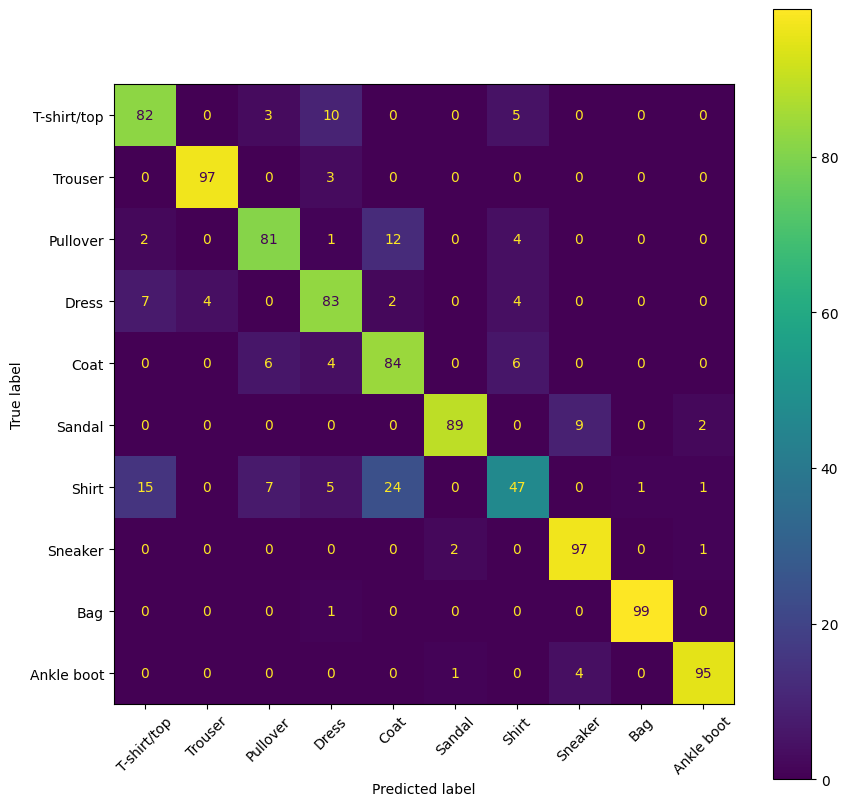

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

outputs = trainer.predict(subset_test_dataset)
print(outputs)

y_true = outputs.label_ids
y_pred = outputs.predictions.argmax(1)

labels = list(classes)
matrix = confusion_matrix(y_true, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=labels)
_, ax = plt.subplots(figsize=(10, 10))
display.plot(xticks_rotation=45, ax=ax)
plt.show()

# 3. CvT 실습

In [ ]:
#10.20 CvT 모델 이미지 데이터 전처리
import torch
from torchvision import transforms
from transformers import AutoImageProcessor

image_processor = AutoImageProcessor.from_pretrained(
    pretrained_model_name_or_path = "microsoft/cvt-21"
)

transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Resize(
            size = (
                image_processor.size["shortest_edge"],
                image_processor.size["shortest_edge"]
            )
        ),
        transforms.Lambda(
            lambda x: torch.cat([x, x, x], 0)
        ),
        transforms.Normalize(
            mean = image_processor.image_mean,
            std = image_processor.image_std
        )
    ]
)

print(f"size : {image_processor.size}")
print(f"mean : {image_processor.image_mean}")
print(f"std : {image_processor.image_std}")

preprocessor_config.json:   0%|          | 0.00/266 [00:00<?, ?B/s]

size : SizeDict(height=None, width=None, longest_edge=None, shortest_edge=224, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
mean : (0.485, 0.456, 0.406)
std : (0.229, 0.224, 0.225)


In [ ]:
#10.21 사전학습된 CvT 모델
from transformers import CvtForImageClassification

model = CvtForImageClassification.from_pretrained(
    pretrained_model_name_or_path='microsoft/cvt-21',
    num_labels=len(train_dataset.classes),
    id2label={idx: label for label, idx in train_dataset.class_to_idx.items()},
    label2id=train_dataset.class_to_idx,
    ignore_mismatched_sizes=True
)

for main_name, main_module in model.named_children():
  print(main_name)
  for sub_name, sub_module in main_module.named_children():
    print("L", sub_name)
    for ssub_name, ssub_module in sub_module.named_children():
      print("  L", ssub_name)
      for sssub_name, sssub_module in ssub_module.named_children():
        print('   L', sssub_name)


config.json:   0%|          | 0.00/70.3k [00:00<?, ?B/s]

[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  127MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/731 [00:00<?, ?it/s]

[transformers] CvtForImageClassification LOAD REPORT from: microsoft/cvt-21
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 384]) vs model:torch.Size([10, 384])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


cvt
L encoder
  L stages
   L 0
   L 1
   L 2
layernorm
classifier


In [ ]:
#10.22 CvT 모델의 스테이지 구조
stages = model.cvt.encoder.stages
print(stages[0])

CvtStage(
  (embedding): CvtEmbeddings(
    (convolution_embeddings): CvtConvEmbeddings(
      (projection): Conv2d(3, 64, kernel_size=(7, 7), stride=(4, 4), padding=(2, 2))
      (normalization): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    )
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (layers): Sequential(
    (0): CvtLayer(
      (attention): CvtAttention(
        (attention): CvtSelfAttention(
          (convolution_projection_query): CvtSelfAttentionProjection(
            (convolution_projection): CvtSelfAttentionConvProjection(
              (convolution): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
              (normalization): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            )
            (linear_projection): CvtSelfAttentionLinearProjection()
          )
          (convolution_projection_key): CvtSelfAttentionProjection(
            (convolution_projection): CvtSelfAtte

In [ ]:
#10.23 셀프 어텐션 적용
batch = next(iter(train_dataloader))
print('이미지 차원:', batch['pixel_values'].shape)

patch_emb_output = stages[0].embedding(batch['pixel_values'])
print('패치 임베딩 차원:', patch_emb_output.shape)

batch_size, num_channels, height, width = patch_emb_output.shape
hidden_state = patch_emb_output.view(batch_size, num_channels, height * width).permute(0, 2, 1)
print('셀프 어텐션 입력 차원:', hidden_state.shape)

attention_output = stages[0].layers[0].attention.attention(hidden_state, height, width)
print('셀프 어텐션 출력 차원:', attention_output.shape)

이미지 차원: torch.Size([32, 3, 224, 224])
패치 임베딩 차원: torch.Size([32, 64, 56, 56])
셀프 어텐션 입력 차원: torch.Size([32, 3136, 64])
셀프 어텐션 출력 차원: torch.Size([32, 3136, 64])


In [ ]:
#10.24 CvT 모델 학습
import torch
import evaluate
import numpy as np
from itertools import chain
from collections import defaultdict
from torch.utils.data import Subset
from torchvision import datasets
from torchvision import transforms
from transformers import AutoImageProcessor
from transformers import CvtForImageClassification
from transformers import TrainingArguments, Trainer

def subset_sampler(dataset, classes, max_len):
  target_idx = defaultdict(list)
  for idx, label in enumerate (dataset.train_labels):
    target_idx[int(label)].append(idx)

  indices = list(
      chain.from_iterable(
          [target_idx[idx][:max_len] for idx in range(len(classes))]
      )
  )

  return Subset(dataset, indices)

def model_init(classes, class_to_idx):
  model = CvtForImageClassification.from_pretrained(
      pretrained_model_name_or_path="microsoft/cvt-21",
      num_labels=len(classes),
      id2label={idx: label for label, idx in class_to_idx.items()},
      label2id=class_to_idx,
      ignore_mismatched_sizes=True
  )
  return model

def collator(data, transform):
  images, labels = zip(*data)
  pixel_values = torch.stack([transform(image) for image in images])
  labels = torch.tensor([label for label in labels])
  return {"pixel_values": pixel_values, "labels": labels}

def compute_metrics(eval_pred):
  metric = evaluate.load('f1')
  predictions, labels = eval_pred
  predictions = np.argmax(predictions, axis=1)
  macro_f1 = metric.compute(
      predictions=predictions, references=labels, average='macro'
  )
  return macro_f1

train_dataset = datasets.FashionMNIST(root="../datasets", download=True, train=True)
test_dataset = datasets.FashionMNIST(root="../datasets", download=True, train=False)

classes = train_dataset.classes
class_to_idx = train_dataset.class_to_idx

subset_train_dataset = subset_sampler(
      dataset = train_dataset, classes=train_dataset.classes, max_len=200
)
subset_test_dataset = subset_sampler(
      dataset = test_dataset, classes=test_dataset.classes, max_len=100
)

image_processor = AutoImageProcessor.from_pretrained(
    pretrained_model_name_or_path = "microsoft/cvt-21"
)

transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Resize(
            size = (
                image_processor.size["shortest_edge"],
                image_processor.size["shortest_edge"]
            )
        ),
        transforms.Lambda(
            lambda x: torch.cat([x, x, x], 0)
        ),
        transforms.Normalize(
            mean = image_processor.image_mean,
            std = image_processor.image_std
        )
    ]
)

args = TrainingArguments(
    output_dir="../models/CvT-FashionMNIST",
    save_strategy = "epoch",
    eval_strategy = "epoch",
    learning_rate = 1e-5,
    per_device_train_batch_size = 16,
    per_device_eval_batch_size = 16,
    num_train_epochs = 2,
    weight_decay = 0.001,
    load_best_model_at_end = True,
    metric_for_best_model = "f1",
    #logging_dir = "logs",
    logging_steps = 125,
    remove_unused_columns = False,
    seed = 7
)

trainer = Trainer(
    model_init=lambda x: model_init(classes, class_to_idx),
    args = args,
    train_dataset = subset_train_dataset,
    eval_dataset = subset_test_dataset,
    data_collator = lambda x: collator(x, transform),
    compute_metrics = compute_metrics,
    processing_class = image_processor,
)
trainer.train()

/usr/local/lib/python3.13/dist-packages/torchvision/datasets/mnist.py:66: UserWarning: train_labels has been renamed targets
  warnings.warn("train_labels has been renamed targets")
[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/731 [00:00<?, ?it/s]

[transformers] CvtForImageClassification LOAD REPORT from: microsoft/cvt-21
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 384]) vs model:torch.Size([10, 384])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/731 [00:00<?, ?it/s]

[transformers] CvtForImageClassification LOAD REPORT from: microsoft/cvt-21
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 384]) vs model:torch.Size([10, 384])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Epoch,Training Loss,Validation Loss,F1
1,1.580734,0.837869,0.787531
2,1.112414,0.653314,0.811904


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=250, training_loss=1.3465736694335937, metrics={'train_runtime': 115.6646, 'train_samples_per_second': 34.583, 'train_steps_per_second': 2.161, 'total_flos': 1.12865458470912e+17, 'train_loss': 1.3465736694335937, 'epoch': 2.0})

PredictionOutput(predictions=array([[ 3.7091947e+00, -1.7972728e+00, -1.2980410e+00, ...,
        -1.5756824e+00, -5.4860955e-01, -5.5715579e-01],
       [ 1.4126931e+00,  1.9599024e+00, -3.1969967e-01, ...,
        -5.9922528e-01, -8.6276484e-01, -1.1101716e+00],
       [ 2.4117258e+00, -1.9371947e+00,  9.9373907e-01, ...,
        -2.1072237e+00, -2.5862110e-01, -3.0106920e-01],
       ...,
       [-5.5061263e-01, -1.2196782e+00, -3.0477437e-01, ...,
         3.2396811e-01,  1.5787760e+00,  2.8604043e+00],
       [-9.4646108e-01, -1.4144868e+00, -7.1342129e-01, ...,
         1.4508003e+00,  7.6071846e-01,  3.9871893e+00],
       [ 2.6894512e-02, -1.2650537e+00, -1.0399729e+00, ...,
        -2.3718493e-03,  3.3195198e-01,  4.5027957e+00]], dtype=float32), label_ids=array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
     

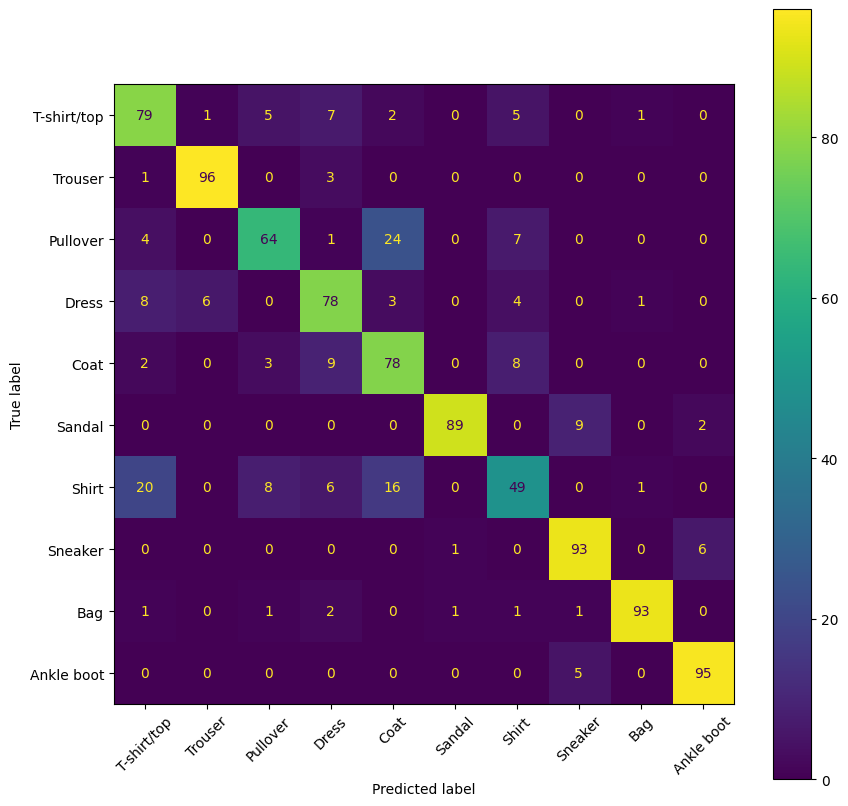

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

outputs = trainer.predict(subset_test_dataset)
print(outputs)

y_true = outputs.label_ids
y_pred = outputs.predictions.argmax(1)

labels = list(classes)
matrix = confusion_matrix(y_true, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=labels)
_, ax = plt.subplots(figsize=(10, 10))
display.plot(xticks_rotation=45, ax=ax)
plt.show()